In [ ]:

from google.colab import files

uploaded = files.upload()


Saving Loan_Portfolio_Insight_Dataset.zip to Loan_Portfolio_Insight_Dataset.zip


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

zip_name = next(iter(uploaded))

with zipfile.ZipFile(zip_name, "r") as z:
    loans = pd.read_csv(z.open("loans.csv"))
    customers = pd.read_csv(z.open("customers.csv"))
    payments = pd.read_csv(z.open("payments.csv"))
    accounts = pd.read_csv(z.open("accounts.csv"))
    history = pd.read_csv(z.open("history.csv"))

print("All datasets loaded successfully!")


All datasets loaded successfully!


In [ ]:

print("Loans:", loans.shape)
print("Customers:", customers.shape)
print("Payments:", payments.shape)
print("Accounts:", accounts.shape)
print("History:", history.shape)

display(loans.head())


Loans: (500, 7)
Customers: (500, 4)
Payments: (2260, 8)
Accounts: (500, 3)
History: (500, 3)


,loan_id,customer_id,loan_type,loan_amount,tenure_months,interest_rate,loan_start_date
0,L0001,C0001,Home,64108.0,6,11.43,2025-12-15
1,L0002,C0002,Home,30996.0,36,15.11,2025-02-09
2,L0003,C0003,Business,41337.0,18,13.43,2025-08-21
3,L0004,C0004,Home,63025.0,60,10.25,2024-05-11
4,L0005,C0005,Home,61468.0,36,8.69,2024-12-18


In [ ]:

print("Missing values in customers:")
print(customers.isnull().sum())

print("\nMissing values in payments:")
print(payments.isnull().sum())

print("\nDuplicate payment rows:")
print(payments.duplicated().sum())

print("\nData types:")
print(payments.dtypes)


Missing values in customers:
customer_id     0
income_band    18
occupation      0
region          0
dtype: int64

Missing values in payments:
payment_id        0
loan_id           0
customer_id       0
due_date          0
paid_date         0
payment_amount    1
payment_status    0
delay_days        0
dtype: int64

Duplicate payment rows:
1

Data types:
payment_id         object
loan_id            object
customer_id        object
due_date           object
paid_date          object
payment_amount    float64
payment_status     object
delay_days          int64
dtype: object


In [ ]:

loans["loan_type"] = (
    loans["loan_type"]
    .astype("string")
    .str.strip()
    .str.title()
)

payments = payments.drop_duplicates().copy()

payments["due_date"] = pd.to_datetime(
    payments["due_date"], errors="coerce"
)

payments["paid_date"] = pd.to_datetime(
    payments["paid_date"], errors="coerce"
)

print("Duplicates remaining:", payments.duplicated().sum())
print("Invalid or missing due dates:", payments["due_date"].isna().sum())
print("Invalid or missing paid dates:", payments["paid_date"].isna().sum())


Duplicates remaining: 0
Invalid or missing due dates: 0
Invalid or missing paid dates: 1


In [ ]:

# Keep records with valid payment dates
valid_payments = payments.dropna(
    subset=["due_date", "paid_date"]
).copy()

# Join payments with loan types
data = valid_payments.merge(
    loans[["loan_id", "loan_type"]],
    on="loan_id",
    how="left"
)

# Calculate delay statistics
result = data.groupby("loan_type").agg(
    total_payments=("payment_id", "count"),
    delayed_payments=(
        "payment_status",
        lambda x: (x == "Delayed").sum()
    )
)

result["delay_rate_pct"] = (
    result["delayed_payments"]
    / result["total_payments"] * 100
).round(2)

result = result.sort_values(
    "delay_rate_pct", ascending=False
)

display(result)


,total_payments,delayed_payments,delay_rate_pct
loan_type,,,
Vehicle,355,71,20.00
Home,466,88,18.88
Personal,686,129,18.80
Business,466,75,16.09
Education,285,43,15.09


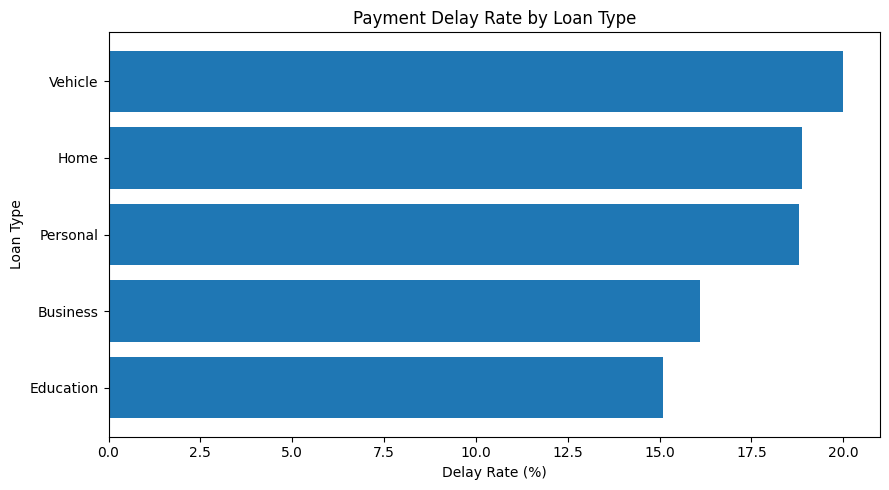

In [ ]:

chart_data = result.sort_values("delay_rate_pct")

plt.figure(figsize=(9, 5))

plt.barh(
    chart_data.index,
    chart_data["delay_rate_pct"]
)

plt.xlabel("Delay Rate (%)")
plt.ylabel("Loan Type")
plt.title("Payment Delay Rate by Loan Type")
plt.tight_layout()
plt.show()


In [ ]:

# Start with payment records and remove exact duplicates
model_data = payments.drop_duplicates().copy()

# Keep records with valid payment dates
model_data["due_date"] = pd.to_datetime(
    model_data["due_date"], errors="coerce"
)
model_data["paid_date"] = pd.to_datetime(
    model_data["paid_date"], errors="coerce"
)

model_data = model_data.dropna(
    subset=["due_date", "paid_date", "payment_status"]
)

# Join loan details
model_data = model_data.merge(
    loans, on=["loan_id", "customer_id"], how="left"
)

# Join customer details
model_data = model_data.merge(
    customers, on="customer_id", how="left"
)

# Join account information
model_data = model_data.merge(
    accounts, on="customer_id", how="left"
)

# Join previous repayment history
model_data = model_data.merge(
    history, on="customer_id", how="left"
)

print("Combined dataset shape:", model_data.shape)
display(model_data.head())


Combined dataset shape: (2258, 20)


,payment_id,loan_id,customer_id,due_date,paid_date,payment_amount,payment_status,delay_days,loan_type,loan_amount,tenure_months,interest_rate,loan_start_date,income_band,occupation,region,balance_band,relationship_months,past_delays_count,restructuring_flag
0,P000001,L0001,C0001,2026-01-15,2026-01-12,10786.44,On-Time,0,Home,64108.0,6,11.43,2025-12-15,Upper-Middle,Business,Central,Medium,91,0,0
1,P000002,L0001,C0001,2026-02-15,2026-02-12,10786.44,On-Time,0,Home,64108.0,6,11.43,2025-12-15,Upper-Middle,Business,Central,Medium,91,0,0
2,P000003,L0001,C0001,2026-03-15,2026-03-13,10786.44,On-Time,0,Home,64108.0,6,11.43,2025-12-15,Upper-Middle,Business,Central,Medium,91,0,0
3,P000005,L0002,C0002,2025-04-09,2025-05-07,871.84,Delayed,28,Home,30996.0,36,15.11,2025-02-09,Lower-Middle,Other,North,Low,46,2,0
4,P000006,L0002,C0002,2025-05-09,2025-05-07,871.84,On-Time,0,Home,30996.0,36,15.11,2025-02-09,Lower-Middle,Other,North,Low,46,2,0


In [ ]:

# Remove records with unexpected target labels
model_data = model_data[
    model_data["payment_status"].isin(["Delayed", "On-Time"])
].copy()

# Create a numeric target: 1 = delayed, 0 = on-time
model_data["delay_target"] = (
    model_data["payment_status"] == "Delayed"
).astype(int)

# Select useful input features
feature_columns = [
    "loan_type",
    "loan_amount",
    "tenure_months",
    "interest_rate",
    "income_band",
    "occupation",
    "region",
    "balance_band",
    "relationship_months",
    "past_delays_count",
    "restructuring_flag"
]

X = model_data[feature_columns].copy()
y = model_data["delay_target"]

print("Input feature shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts().rename({
    0: "On-Time",
    1: "Delayed"
}))


Input feature shape: (2258, 11)

Target distribution:
delay_target
On-Time    1852
Delayed     406
Name: count, dtype: int64


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

# Process numeric data
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical data
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [ ]:

# Split before fitting preprocessing to avoid data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Build the full machine learning pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train
model.fit(X_train, y_train)

# Predict unseen test records
y_pred = model.predict(X_test)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Model training completed!")


Training records: 1806
Testing records: 452
Model training completed!


In [ ]:

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Accuracy : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["On-Time", "Delayed"],
    zero_division=0
))


Accuracy : 0.8208 (82.08%)
Precision: 0.0000
Recall   : 0.0000
F1-score : 0.0000

Classification Report:
              precision    recall  f1-score   support

     On-Time       0.82      1.00      0.90       371
     Delayed       0.00      0.00      0.00        81

    accuracy                           0.82       452
   macro avg       0.41      0.50      0.45       452
weighted avg       0.67      0.82      0.74       452



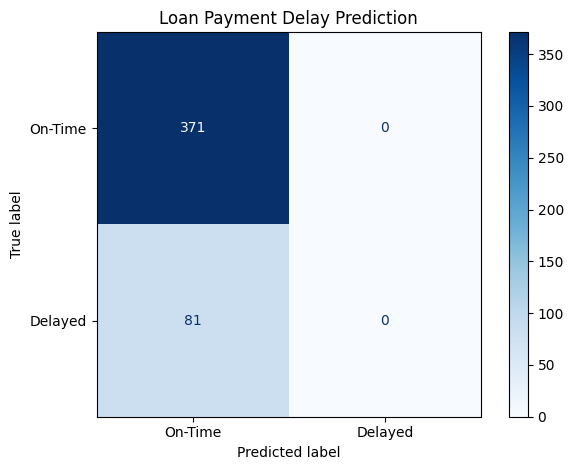

In [ ]:

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["On-Time", "Delayed"],
    cmap="Blues"
)

plt.title("Loan Payment Delay Prediction")
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Give more weight to the minority class
balanced_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Train on the same training split
balanced_model.fit(X_train, y_train)

# Predict the test data
y_pred_balanced = balanced_model.predict(X_test)

print("Balanced model training completed!")


Balanced model training completed!


Accuracy : 0.6106
Precision: 0.2086
Recall   : 0.4198
F1-score : 0.2787

Classification Report:
              precision    recall  f1-score   support

     On-Time       0.84      0.65      0.73       371
     Delayed       0.21      0.42      0.28        81

    accuracy                           0.61       452
   macro avg       0.52      0.54      0.51       452
weighted avg       0.72      0.61      0.65       452



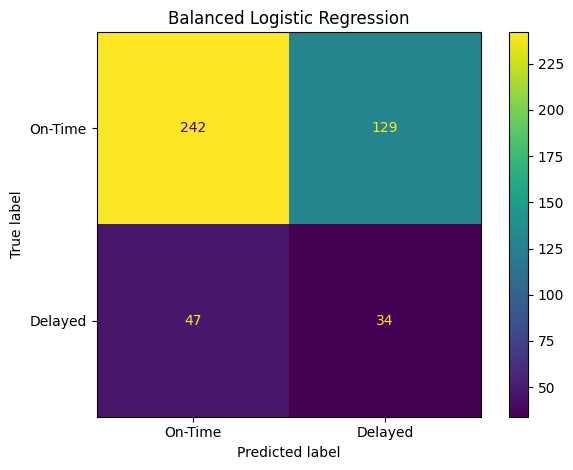

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print(f"Accuracy : {accuracy_score(y_test, y_pred_balanced):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_balanced, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_balanced, zero_division=0):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred_balanced, zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_balanced,
    target_names=["On-Time", "Delayed"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_balanced,
    display_labels=["On-Time", "Delayed"]
)
plt.title("Balanced Logistic Regression")
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Create the Decision Tree pipeline
tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ))
])

# Train using the existing training data
tree_model.fit(X_train, y_train)

# Predict the same test data
y_pred_tree = tree_model.predict(X_test)

print("Decision Tree trained successfully!")


Decision Tree trained successfully!


Decision Tree Performance
-----------------------------------
Accuracy : 0.5730
Precision: 0.2333
Recall   : 0.6049
F1-score : 0.3368

Classification Report:
              precision    recall  f1-score   support

     On-Time       0.87      0.57      0.69       371
     Delayed       0.23      0.60      0.34        81

    accuracy                           0.57       452
   macro avg       0.55      0.59      0.51       452
weighted avg       0.75      0.57      0.62       452



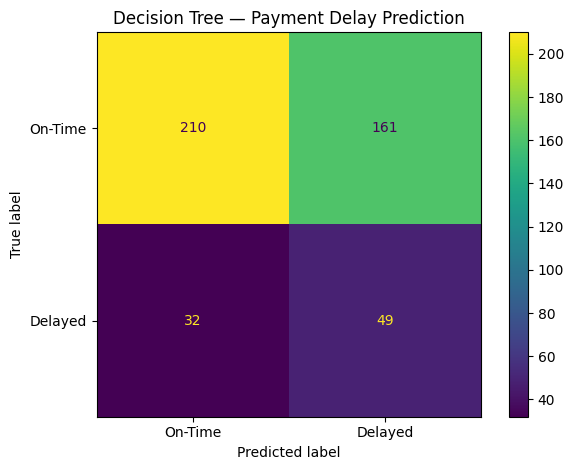

In [ ]:

print("Decision Tree Performance")
print("-" * 35)

print(f"Accuracy : {accuracy_score(y_test, y_pred_tree):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_tree, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_tree, zero_division=0):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred_tree, zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tree,
    target_names=["On-Time", "Delayed"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tree,
    display_labels=["On-Time", "Delayed"]
)
plt.title("Decision Tree — Payment Delay Prediction")
plt.tight_layout()
plt.show()


In [ ]:

comparison = pd.DataFrame({
    "Model": [
        "Balanced Logistic Regression",
        "Balanced Decision Tree"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_balanced),
        accuracy_score(y_test, y_pred_tree)
    ],
    "Delayed Precision": [
        precision_score(y_test, y_pred_balanced, zero_division=0),
        precision_score(y_test, y_pred_tree, zero_division=0)
    ],
    "Delayed Recall": [
        recall_score(y_test, y_pred_balanced, zero_division=0),
        recall_score(y_test, y_pred_tree, zero_division=0)
    ],
    "Delayed F1-score": [
        f1_score(y_test, y_pred_balanced, zero_division=0),
        f1_score(y_test, y_pred_tree, zero_division=0)
    ]
})

display(comparison.round(4))


,Model,Accuracy,Delayed Precision,Delayed Recall,Delayed F1-score
0,Balanced Logistic Regression,0.6106,0.2086,0.4198,0.2787
1,Balanced Decision Tree,0.5730,0.2333,0.6049,0.3368


In [ ]:

# Export combined dataset to CSV
model_data.to_csv(
    "loan_portfolio_analysis.csv",
    index=False
)

# Download the file to your computer
from google.colab import files
files.download("loan_portfolio_analysis.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>